In [ ]:
print('Hello World')

Hello World


#**Importing_Dataset**

In [ ]:
!pip install -q kaggle

In [ ]:
from google.colab import files

files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"prashant017","key":"74bc2209ffee86ec7cb141e181ba2f8c"}'}

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/RPS_CNN_Project"

DATASET_DIR = os.path.join(
    PROJECT_DIR,
    "Rock-Paper-Scissors"
)

TRAIN_DIR = os.path.join(DATASET_DIR, "train")
TEST_DIR = os.path.join(DATASET_DIR, "test")
VAL_DIR = os.path.join(DATASET_DIR, "validation")

print("Dataset:", DATASET_DIR)
print("Train:", TRAIN_DIR)
print("Test:", TEST_DIR)

Dataset: /content/drive/MyDrive/RPS_CNN_Project/Rock-Paper-Scissors
Train: /content/drive/MyDrive/RPS_CNN_Project/Rock-Paper-Scissors/train
Test: /content/drive/MyDrive/RPS_CNN_Project/Rock-Paper-Scissors/test


In [ ]:
import shutil
import os

source = "/content/rps_dataset/Rock-Paper-Scissors"
destination = "/content/drive/MyDrive/RPS_CNN_Project/Rock-Paper-Scissors"

if not os.path.exists(destination):
    shutil.copytree(source, destination)
    print("Dataset copied to Google Drive.")
else:
    print("Dataset already exists in Google Drive. Skipping copy.")

Dataset already exists in Google Drive. Skipping copy.


In [ ]:
print("Dataset exists:", os.path.exists(DATASET_DIR))
print("Train exists:", os.path.exists(TRAIN_DIR))
print("Test exists:", os.path.exists(TEST_DIR))
print("Validation exists:", os.path.exists(VAL_DIR))

if os.path.exists(TRAIN_DIR):
    print("\nClasses:", os.listdir(TRAIN_DIR))

Dataset exists: True
Train exists: True
Test exists: True
Validation exists: True

Classes: ['paper', 'scissors', 'rock']


#**Data_Inspection**

In [ ]:
for root, dirs, files in os.walk(DATASET_DIR):
    level = root.replace(DATASET_DIR, "").count(os.sep)

    if level <= 2:
        print(root)

/content/drive/MyDrive/RPS_CNN_Project/Rock-Paper-Scissors
/content/drive/MyDrive/RPS_CNN_Project/Rock-Paper-Scissors/test
/content/drive/MyDrive/RPS_CNN_Project/Rock-Paper-Scissors/test/scissors
/content/drive/MyDrive/RPS_CNN_Project/Rock-Paper-Scissors/test/rock
/content/drive/MyDrive/RPS_CNN_Project/Rock-Paper-Scissors/test/paper
/content/drive/MyDrive/RPS_CNN_Project/Rock-Paper-Scissors/validation
/content/drive/MyDrive/RPS_CNN_Project/Rock-Paper-Scissors/train
/content/drive/MyDrive/RPS_CNN_Project/Rock-Paper-Scissors/train/paper
/content/drive/MyDrive/RPS_CNN_Project/Rock-Paper-Scissors/train/scissors
/content/drive/MyDrive/RPS_CNN_Project/Rock-Paper-Scissors/train/rock


In [ ]:
print("Training classes:", os.listdir(TRAIN_DIR))
print("Testing classes :", os.listdir(TEST_DIR))

Training classes: ['paper', 'scissors', 'rock']
Testing classes : ['scissors', 'rock', 'paper']


In [ ]:
classes = ["paper", "rock", "scissors"]

for split_name, split_dir in [
    ("TRAIN", TRAIN_DIR),
    ("TEST", TEST_DIR)
]:

    print(f"\n{split_name}")
    print("-" * 30)

    for cls in classes:
        class_dir = os.path.join(split_dir, cls)

        images = [
            f for f in os.listdir(class_dir)
            if f.lower().endswith((".png", ".jpg", ".jpeg"))
        ]

        print(f"{cls:10} : {len(images)}")


TRAIN
------------------------------
paper      : 840
rock       : 840
scissors   : 840

TEST
------------------------------
paper      : 124
rock       : 124
scissors   : 124


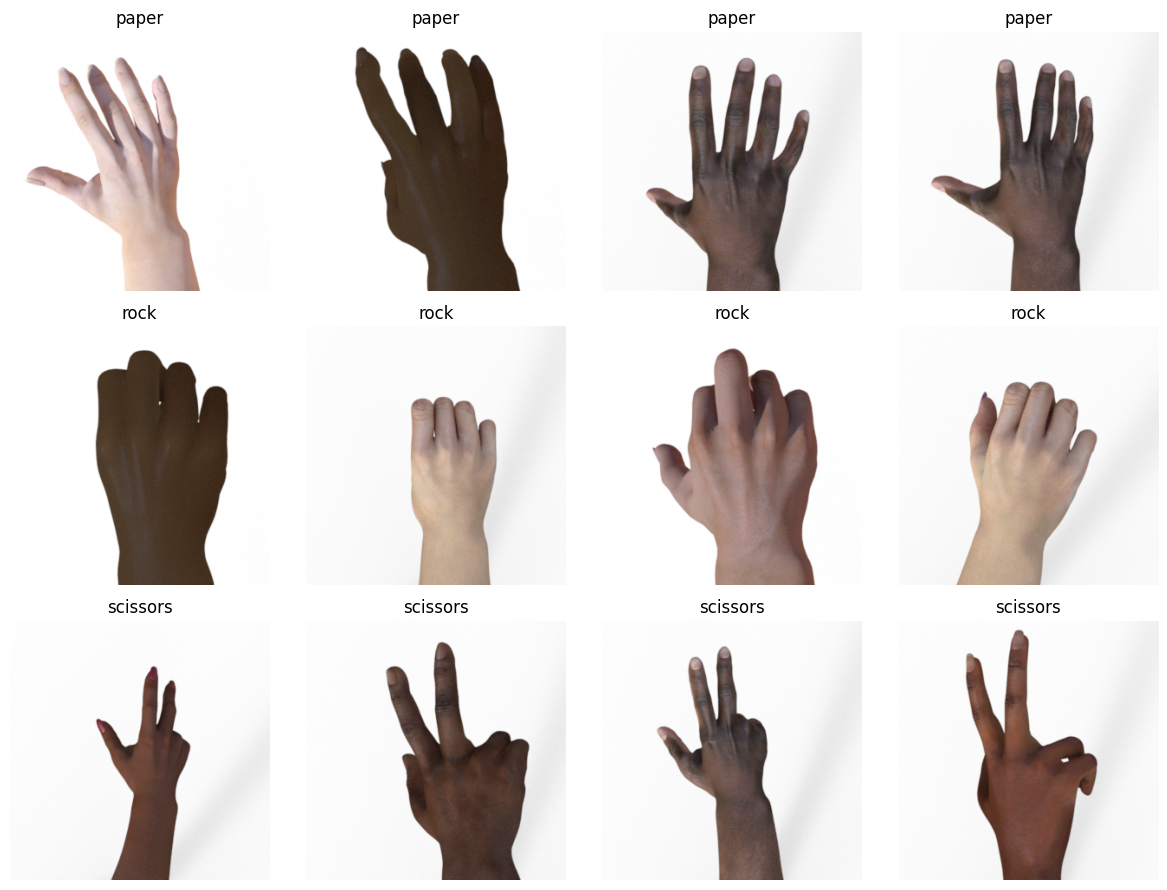

In [ ]:
import random
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for row, cls in enumerate(classes):

    class_dir = os.path.join(TRAIN_DIR, cls)

    image_files = [
        f for f in os.listdir(class_dir)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    selected = random.sample(image_files, 4)

    for col, image_file in enumerate(selected):

        image_path = os.path.join(class_dir, image_file)

        image = Image.open(image_path)

        axes[row, col].imshow(image)
        axes[row, col].set_title(cls)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from collections import Counter

image_sizes = Counter()

for cls in classes:

    class_dir = os.path.join(TRAIN_DIR, cls)

    image_files = [
        f for f in os.listdir(class_dir)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    for image_file in image_files:

        image_path = os.path.join(class_dir, image_file)

        with Image.open(image_path) as img:
            image_sizes[img.size] += 1

print("Unique image sizes:", len(image_sizes))

print("\nMost common sizes:")
for size, count in image_sizes.most_common(10):
    print(size, "→", count)

Unique image sizes: 1

Most common sizes:
(300, 300) → 2520


In [ ]:
image_modes = Counter()

for cls in classes:

    class_dir = os.path.join(TRAIN_DIR, cls)

    image_files = [
        f for f in os.listdir(class_dir)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    for image_file in image_files:

        image_path = os.path.join(class_dir, image_file)

        with Image.open(image_path) as img:
            image_modes[img.mode] += 1

print(image_modes)

Counter({'RGBA': 2520})


In [ ]:
corrupted_images = []

for cls in classes:

    class_dir = os.path.join(TRAIN_DIR, cls)

    image_files = [
        f for f in os.listdir(class_dir)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    for image_file in image_files:

        image_path = os.path.join(class_dir, image_file)

        try:
            with Image.open(image_path) as img:
                img.verify()

        except Exception:
            corrupted_images.append(image_path)

print("Corrupted images:", len(corrupted_images))

Corrupted images: 0


#**Data_Loading_for_architecture**

In [ ]:
import torch
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

import numpy as np
import matplotlib.pyplot as plt

In [ ]:
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

PyTorch version: 2.11.0+cu128
Torchvision version: 0.26.0+cu128
Device: cuda


In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((32, 32)),

    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

In [ ]:
eval_transform = transforms.Compose([
    transforms.Resize((32, 32)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

In [ ]:
full_train_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=train_transform
)

print("Total images:", len(full_train_dataset))
print("Classes:", full_train_dataset.classes)
print("Class mapping:", full_train_dataset.class_to_idx)

Total images: 2520
Classes: ['paper', 'rock', 'scissors']
Class mapping: {'paper': 0, 'rock': 1, 'scissors': 2}


In [ ]:
train_size = int(0.9 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size

generator = torch.Generator().manual_seed(42)

train_subset, val_subset = torch.utils.data.random_split(
    full_train_dataset,
    [train_size, val_size],
    generator=generator
)

print("Training samples:", len(train_subset))
print("Validation samples:", len(val_subset))

Training samples: 2268
Validation samples: 252


In [ ]:
train_dataset_full = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=train_transform
)

val_dataset_full = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=eval_transform
)

In [ ]:
train_size = int(0.9 * len(train_dataset_full))
val_size = len(train_dataset_full) - train_size

generator = torch.Generator().manual_seed(42)

indices = torch.randperm(
    len(train_dataset_full),
    generator=generator
).tolist()

train_indices = indices[:train_size]
val_indices = indices[train_size:]

In [ ]:
train_dataset = Subset(
    train_dataset_full,
    train_indices
)

val_dataset = Subset(
    val_dataset_full,
    val_indices
)

In [ ]:
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

Training samples: 2268
Validation samples: 252


In [ ]:
test_dataset = datasets.ImageFolder(
    root=TEST_DIR,
    transform=eval_transform
)

print("Test samples:", len(test_dataset))
print("Classes:", test_dataset.classes)

Test samples: 372
Classes: ['paper', 'rock', 'scissors']


In [ ]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [ ]:
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 71
Validation batches: 8
Test batches: 12


In [ ]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels:", labels[:10])

Image batch shape: torch.Size([32, 3, 32, 32])
Label batch shape: torch.Size([32])
Labels: tensor([0, 0, 2, 1, 0, 1, 1, 2, 0, 1])


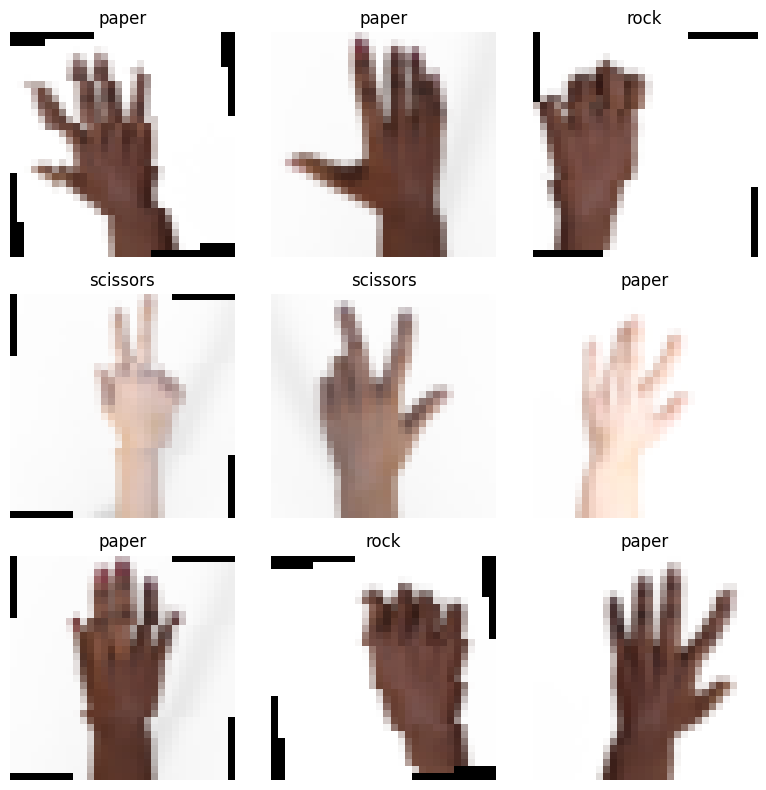

In [ ]:
images, labels = next(iter(train_loader))

images = images[:9]
labels = labels[:9]

mean = torch.tensor([0.5, 0.5, 0.5]).view(3, 1, 1)
std = torch.tensor([0.5, 0.5, 0.5]).view(3, 1, 1)

images = images * std + mean
images = torch.clamp(images, 0, 1)

fig, axes = plt.subplots(3, 3, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].permute(1, 2, 0))
    ax.set_title(full_train_dataset.classes[labels[i]])
    ax.axis("off")

plt.tight_layout()
plt.show()

#**Buliding LeNet-5 Architecture**

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [ ]:
class LeNet5(nn.Module):

    def __init__(self, num_classes=3):

        super().__init__()

        # C1
        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=6,
            kernel_size=5
        )

        # S2
        self.pool1 = nn.AvgPool2d(
            kernel_size=2,
            stride=2
        )

        # C3
        self.conv2 = nn.Conv2d(
            in_channels=6,
            out_channels=16,
            kernel_size=5
        )

        # S4
        self.pool2 = nn.AvgPool2d(
            kernel_size=2,
            stride=2
        )

        # C5
        self.conv3 = nn.Conv2d(
            in_channels=16,
            out_channels=120,
            kernel_size=5
        )

        # F6
        self.fc1 = nn.Linear(
            in_features=120,
            out_features=84
        )

        # Output layer
        self.fc2 = nn.Linear(
            in_features=84,
            out_features=num_classes
        )

    def forward(self, x):

        # C1 → S2
        x = F.relu(self.conv1(x))
        x = self.pool1(x)

        # C3 → S4
        x = F.relu(self.conv2(x))
        x = self.pool2(x)

        # C5
        x = F.relu(self.conv3(x))

        # Flatten
        x = torch.flatten(x, start_dim=1)

        # F6
        x = F.relu(self.fc1(x))

        # Output
        x = self.fc2(x)

        return x

In [ ]:
model = LeNet5(num_classes=3)

model = model.to(device)

print(model)

LeNet5(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool1): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (pool2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (conv3): Conv2d(16, 120, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=120, out_features=84, bias=True)
  (fc2): Linear(in_features=84, out_features=3, bias=True)
)


In [ ]:
dummy_input = torch.randn(1, 3, 32, 32).to(device)

output = model(dummy_input)

print("Input shape :", dummy_input.shape)
print("Output shape:", output.shape)

Input shape : torch.Size([1, 3, 32, 32])
Output shape: torch.Size([1, 3])


In [ ]:
dummy_input = torch.randn(1, 3, 32, 32).to(device)

output = model(dummy_input)

In [ ]:
total_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Trainable parameters: {total_params:,}")

Trainable parameters: 61,411


#**Training_with_architecture**

In [ ]:
criterion = nn.CrossEntropyLoss()

In [ ]:
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01,
    momentum=0.9
)

In [ ]:
print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    momentum: 0.9
    nesterov: False
    weight_decay: 0
)


In [ ]:
optimizer.zero_grad()

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        # 1. Clear previous gradients
        optimizer.zero_grad()

        # 2. Forward pass
        outputs = model(images)

        # 3. Calculate loss
        loss = criterion(outputs, labels)

        # 4. Backpropagation
        loss.backward()

        # 5. Update weights
        optimizer.step()

        # Statistics
        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [ ]:
model.train()

LeNet5(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool1): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (pool2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (conv3): Conv2d(16, 120, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=120, out_features=84, bias=True)
  (fc2): Linear(in_features=84, out_features=3, bias=True)
)

In [ ]:
def evaluate(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            # Forward pass
            outputs = model(images)

            # Loss
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            # Predictions
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [ ]:
EPOCHS = 15

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = evaluate(
        model,
        val_loader,
        criterion,
        device
    )

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_acc:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_acc:.2f}%"
    )

Epoch [01/15] | Train Loss: 1.0989 | Train Acc: 32.85% | Val Loss: 1.0970 | Val Acc: 29.37%
Epoch [02/15] | Train Loss: 1.0767 | Train Acc: 47.05% | Val Loss: 1.0143 | Val Acc: 51.59%
Epoch [03/15] | Train Loss: 0.7744 | Train Acc: 65.83% | Val Loss: 0.4926 | Val Acc: 79.37%
Epoch [04/15] | Train Loss: 0.1811 | Train Acc: 94.00% | Val Loss: 0.0862 | Val Acc: 97.62%
Epoch [05/15] | Train Loss: 0.0865 | Train Acc: 97.75% | Val Loss: 0.0476 | Val Acc: 99.21%
Epoch [06/15] | Train Loss: 0.0736 | Train Acc: 97.35% | Val Loss: 0.0712 | Val Acc: 98.41%
Epoch [07/15] | Train Loss: 0.0683 | Train Acc: 97.44% | Val Loss: 0.0206 | Val Acc: 99.60%
Epoch [08/15] | Train Loss: 0.0517 | Train Acc: 98.50% | Val Loss: 0.0537 | Val Acc: 98.02%
Epoch [09/15] | Train Loss: 0.0328 | Train Acc: 99.25% | Val Loss: 0.0089 | Val Acc: 99.60%
Epoch [10/15] | Train Loss: 0.0171 | Train Acc: 99.38% | Val Loss: 0.0064 | Val Acc: 99.60%
Epoch [11/15] | Train Loss: 0.0205 | Train Acc: 99.29% | Val Loss: 0.0064 | Val 

# **Evaluation**

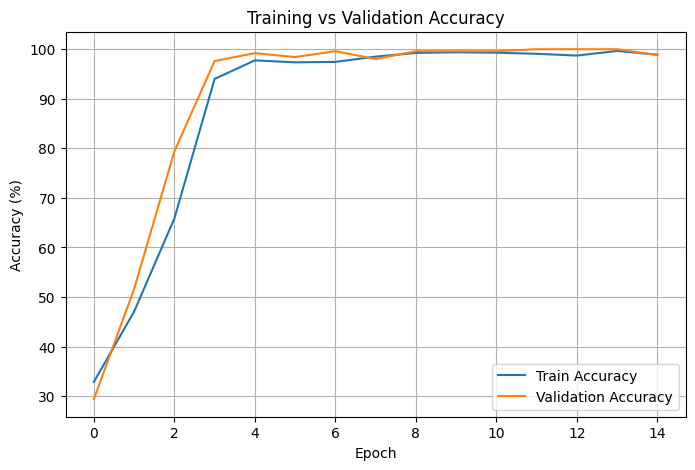

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(train_accuracies, label="Train Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid()

plt.show()

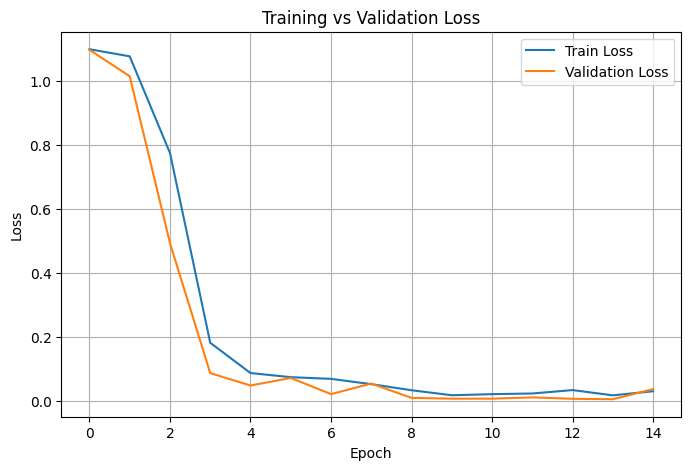

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid()

plt.show()

In [ ]:
test_loss, test_acc = evaluate(
    model,
    test_loader,
    criterion,
    device
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.2f}%")

Test Loss: 0.6714
Test Accuracy: 75.81%


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        predictions = torch.argmax(outputs, dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

In [ ]:
cm = confusion_matrix(
    all_labels,
    all_predictions
)

print(cm)

[[ 78  19  27]
 [ 16 101   7]
 [  0  21 103]]


In [ ]:
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=test_dataset.classes
    )
)

              precision    recall  f1-score   support

       paper       0.83      0.63      0.72       124
        rock       0.72      0.81      0.76       124
    scissors       0.75      0.83      0.79       124

    accuracy                           0.76       372
   macro avg       0.77      0.76      0.76       372
weighted avg       0.77      0.76      0.76       372



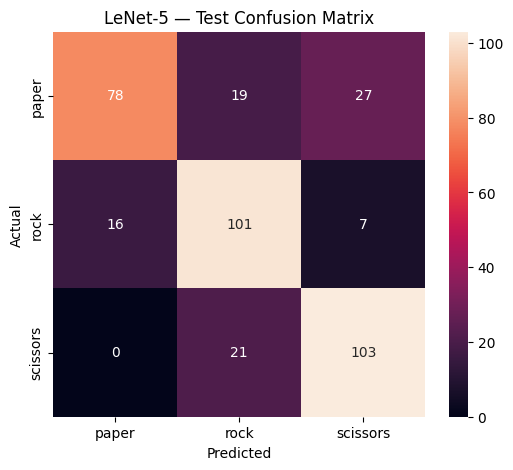

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=test_dataset.classes,
    yticklabels=test_dataset.classes
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("LeNet-5 — Test Confusion Matrix")

plt.show()

#**ResNet_Architecture**

In [ ]:
from torchvision import transforms

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

In [ ]:
train_transform_tl = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

In [ ]:
eval_transform_tl = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

In [ ]:
from torchvision import datasets
from torch.utils.data import Subset

train_dataset_tl_full = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=train_transform_tl
)

val_dataset_tl_full = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=eval_transform_tl
)

In [ ]:
train_dataset_tl = Subset(
    train_dataset_tl_full,
    train_indices
)

val_dataset_tl = Subset(
    val_dataset_tl_full,
    val_indices
)

In [ ]:
test_dataset_tl = datasets.ImageFolder(
    root=TEST_DIR,
    transform=eval_transform_tl
)

In [ ]:
print("Train:", len(train_dataset_tl))
print("Val  :", len(val_dataset_tl))
print("Test :", len(test_dataset_tl))

Train: 2268
Val  : 252
Test : 372


In [ ]:
BATCH_SIZE_TL = 32

train_loader_tl = DataLoader(
    train_dataset_tl,
    batch_size=BATCH_SIZE_TL,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader_tl = DataLoader(
    val_dataset_tl,
    batch_size=BATCH_SIZE_TL,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader_tl = DataLoader(
    test_dataset_tl,
    batch_size=BATCH_SIZE_TL,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [ ]:
images, labels = next(iter(train_loader_tl))

print("Image shape:", images.shape)
print("Label shape:", labels.shape)

Image shape: torch.Size([32, 3, 224, 224])
Label shape: torch.Size([32])


In [ ]:
from torchvision.models import resnet18, ResNet18_Weights

weights = ResNet18_Weights.DEFAULT

resnet18_model = resnet18(weights=weights)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 140MB/s]


In [ ]:
print(resnet18_model.fc)

Linear(in_features=512, out_features=1000, bias=True)


In [ ]:
import torch.nn as nn

resnet18_model.fc = nn.Linear(
    in_features=512,
    out_features=3
)

In [ ]:
print(resnet18_model.fc)

Linear(in_features=512, out_features=3, bias=True)


In [ ]:
for param in resnet18_model.parameters():
    param.requires_grad = False

In [ ]:
for param in resnet18_model.fc.parameters():
    param.requires_grad = True

In [ ]:
resnet18_model = resnet18_model.to(device)

In [ ]:
trainable_params = sum(
    p.numel()
    for p in resnet18_model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in resnet18_model.parameters()
)

print(f"Total parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")

Total parameters     : 11,178,051
Trainable parameters : 1,539


In [ ]:
criterion_tl = nn.CrossEntropyLoss()

optimizer_tl = torch.optim.Adam(
    resnet18_model.fc.parameters(),
    lr=1e-3
)

In [ ]:
train_loss, train_acc = train_one_epoch(
    resnet18_model,
    train_loader_tl,
    criterion_tl,
    optimizer_tl,
    device
)

val_loss, val_acc = evaluate(
    resnet18_model,
    val_loader_tl,
    criterion_tl,
    device
)

print(f"Train Loss: {train_loss:.4f}")
print(f"Train Acc : {train_acc:.2f}%")
print(f"Val Loss  : {val_loss:.4f}")
print(f"Val Acc   : {val_acc:.2f}%")

Train Loss: 0.7552
Train Acc : 70.63%
Val Loss  : 0.4074
Val Acc   : 92.46%


In [ ]:
EPOCHS_TL = 5

for epoch in range(EPOCHS_TL):

    train_loss, train_acc = train_one_epoch(
        resnet18_model,
        train_loader_tl,
        criterion_tl,
        optimizer_tl,
        device
    )

    val_loss, val_acc = evaluate(
        resnet18_model,
        val_loader_tl,
        criterion_tl,
        device
    )

    print(
        f"Epoch [{epoch+1}/{EPOCHS_TL}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_acc:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_acc:.2f}%"
    )

Epoch [1/5] | Train Loss: 0.3634 | Train Acc: 92.15% | Val Loss: 0.2629 | Val Acc: 94.84%
Epoch [2/5] | Train Loss: 0.2378 | Train Acc: 96.25% | Val Loss: 0.2044 | Val Acc: 94.44%
Epoch [3/5] | Train Loss: 0.1823 | Train Acc: 97.00% | Val Loss: 0.1501 | Val Acc: 95.24%
Epoch [4/5] | Train Loss: 0.1665 | Train Acc: 96.87% | Val Loss: 0.1353 | Val Acc: 96.43%
Epoch [5/5] | Train Loss: 0.1416 | Train Acc: 97.44% | Val Loss: 0.1200 | Val Acc: 97.22%


#**Training Unfreezed Model**

In [ ]:
from torchvision.models import resnet18, ResNet18_Weights
import torch.nn as nn

weights = ResNet18_Weights.DEFAULT

resnet18_ft = resnet18(weights=weights)

resnet18_ft.fc = nn.Linear(
    in_features=512,
    out_features=3
)

In [ ]:
for param in resnet18_ft.parameters():
    param.requires_grad = False

In [ ]:
for param in resnet18_ft.layer4.parameters():
    param.requires_grad = True

In [ ]:
for param in resnet18_ft.fc.parameters():
    param.requires_grad = True

In [ ]:
resnet18_ft = resnet18_ft.to(device)

In [ ]:
total_params = sum(
    p.numel()
    for p in resnet18_ft.parameters()
)

trainable_params = sum(
    p.numel()
    for p in resnet18_ft.parameters()
    if p.requires_grad
)

print(f"Total parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")

Total parameters     : 11,178,051
Trainable parameters : 8,395,267


In [ ]:
criterion_ft = nn.CrossEntropyLoss()

optimizer_ft = torch.optim.Adam(
    [
        {
            "params": resnet18_ft.layer4.parameters(),
            "lr": 1e-5
        },
        {
            "params": resnet18_ft.fc.parameters(),
            "lr": 1e-4
        }
    ]
)

In [ ]:
EPOCHS_FT = 5

ft_train_losses = []
ft_train_accs = []

ft_val_losses = []
ft_val_accs = []

for epoch in range(EPOCHS_FT):

    train_loss, train_acc = train_one_epoch(
        resnet18_ft,
        train_loader_tl,
        criterion_ft,
        optimizer_ft,
        device
    )

    val_loss, val_acc = evaluate(
        resnet18_ft,
        val_loader_tl,
        criterion_ft,
        device
    )

    ft_train_losses.append(train_loss)
    ft_train_accs.append(train_acc)

    ft_val_losses.append(val_loss)
    ft_val_accs.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{EPOCHS_FT}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_acc:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_acc:.2f}%"
    )

Epoch [1/5] | Train Loss: 0.5982 | Train Acc: 85.27% | Val Loss: 0.2116 | Val Acc: 99.60%
Epoch [2/5] | Train Loss: 0.1416 | Train Acc: 99.47% | Val Loss: 0.0655 | Val Acc: 100.00%
Epoch [3/5] | Train Loss: 0.0614 | Train Acc: 99.91% | Val Loss: 0.0315 | Val Acc: 100.00%
Epoch [4/5] | Train Loss: 0.0322 | Train Acc: 99.96% | Val Loss: 0.0164 | Val Acc: 100.00%
Epoch [5/5] | Train Loss: 0.0204 | Train Acc: 100.00% | Val Loss: 0.0124 | Val Acc: 100.00%
